# Project 3: Toxic Comment Detection on YouTube

## Notebook 3 of 3: Modelling | Evaluation | Conclusion

**Contents**
1. Problem statement and measure of success
2. Train-test split
3. Baseline score
4. Comparing text preprocessing methods
5. Tuning Naive Bayes, Random Forest and Logistic Regression
6. Selection of production model
7. Decision threshold
8. Evaluation on the test set
9. What the model has learned
10. Error analysis
11. Check against manual labels
12. Conclusion and recommendations

In [1]:
# Import libraries
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, accuracy_score, average_precision_score,
                             classification_report, cohen_kappa_score, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

pd.options.display.max_colwidth = 200
sns.set_style('whitegrid')

# Hide a harmless warning from joblib about worker processes being restarted during grid search
warnings.filterwarnings('ignore', message='A worker stopped while some jobs were given to the executor')

### 1. Problem statement and measure of success

**Problem statement:** The community team of a YouTube channel wants toxic comments to be held automatically for review by a moderator, instead of reading every comment. The goal is to build a classification model that predicts whether a comment is toxic (1) or not toxic (0) from its text.

**Measure of success:** The model is evaluated on the toxic class of a test set that is not used for training or tuning:

* **Recall of at least 0.75** - at least three in four toxic comments are caught.
* **Precision of at least 0.70** - at least seven in ten comments held for review are indeed toxic, so that moderators' time is not wasted and harmless comments are not held back unnecessarily.
* **F1 score** (which combines the two) is used to compare models, and it must be better than the baseline score.

Accuracy is not used to compare models as the classes are imbalanced: a model that never flags any comment would already be right most of the time.

In [2]:
# Import data
df = pd.read_csv('../data/comments_labelled.csv')

# Comments with only stop words are read in as missing values in the processed text columns
text_cols = ['clean_text', 'text_stop', 'text_stem', 'text_lemma']
df[text_cols] = df[text_cols].fillna('')

print(df.shape)
df.isnull().sum().sum()

(32783, 13)


0

In [3]:
df[['text', 'clean_text', 'toxicity', 'is_toxic']].head()

,text,clean_text,toxicity,is_toxic
0,*Watch our Collab on Hungry Fat Chick's channel:* https://www.youtube.com/watch?v=SfR4Jm8fbFA\n *Get this Hoodie for Christmas* 🎄🎁: https://ItsJustWaterWeight.com,watch our collab on hungry fat chicks channel get this hoodie for christmas,0.109391,0
1,Diabetes.,diabetes,0.000752,0
2,Use me as dislike button,use me as dislike button,0.139587,0
3,I was watching one of ur videos and I got ur notification for the video,i was watching one of ur videos and i got ur notification for the video,0.000756,0
4,don’t care + didn’t ask + L + ratio + you fell off + no,dont care didnt ask l ratio you fell off no,0.352240,0


### 2. Train-test split

In [4]:
# 80% of comments for training (and cross-validation), 20% held out for the final evaluation
# Stratified so that both sets have the same share of toxic comments
train, test = train_test_split(df, test_size=0.2, stratify=df['is_toxic'], random_state=42)

y_train = train['is_toxic']
y_test = test['is_toxic']

print(f'Train: {train.shape[0]} comments, {y_train.mean():.1%} toxic')
print(f'Test: {test.shape[0]} comments, {y_test.mean():.1%} toxic')

Train: 26226 comments, 19.4% toxic
Test: 6557 comments, 19.4% toxic


* Each cleaned text appears only once in the data (duplicates were dropped in Notebook 2), so the same comment cannot be in both the train and test sets.
* All comparisons and tuning below are done with 5-fold cross-validation on the train set. The test set is used only once at the end, on the final models.

In [5]:
# Folds used for all cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

### 3. Baseline score

In [6]:
# Baseline: always predict the majority class (not toxic)
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(train['clean_text'], y_train)
y_pred_baseline = baseline.predict(test['clean_text'])

print(f'Baseline accuracy: {accuracy_score(y_test, y_pred_baseline):.4f}')
print(f'Baseline recall: {recall_score(y_test, y_pred_baseline):.4f}')
print(f'Baseline precision: {precision_score(y_test, y_pred_baseline, zero_division=0):.4f}')
print(f'Baseline F1 score: {f1_score(y_test, y_pred_baseline):.4f}')

Baseline accuracy: 0.8062
Baseline recall: 0.0000
Baseline precision: 0.0000
Baseline F1 score: 0.0000


**Comments**

* 80.6% of the comments are not toxic, so a model that labels every comment as not toxic is right 80.6% of the time without learning anything. This is the baseline accuracy that any model must beat.
* However, this baseline does not catch a single toxic comment: its recall, precision and F1 score on the toxic class are all 0. This shows why accuracy is misleading for this problem, and why the models are compared on the F1 score of the toxic class instead.

### 4. Comparing text preprocessing methods

Four versions of the text were prepared in Notebook 2. Each is converted to a matrix of word counts (`CountVectorizer`) or TF-IDF weights (`TfidfVectorizer`) and scored with Naive Bayes and Logistic Regression using default settings, to see which preprocessing method works best for this data.

In [7]:
def cv_scores(pipe, X, y):
    """Return the mean cross-validated F1 score, precision and recall of a pipeline."""
    scores = cross_validate(pipe, X, y, cv=cv, scoring=['f1', 'precision', 'recall'], n_jobs=-1)
    return {'f1': scores['test_f1'].mean(),
            'precision': scores['test_precision'].mean(),
            'recall': scores['test_recall'].mean()}


text_versions = {'clean_text': 'Cleaned only',
                 'text_stop': 'Stop words removed',
                 'text_stem': 'Stop words removed + stemmed',
                 'text_lemma': 'Stop words removed + lemmatized'}

vectorizers = {'CountVectorizer': CountVectorizer, 'TfidfVectorizer': TfidfVectorizer}

classifiers = {'Naive Bayes': MultinomialNB(),
               'Logistic Regression': LogisticRegression(solver='liblinear', max_iter=1000)}

results = []
for col, description in text_versions.items():
    for vec_name, vectorizer in vectorizers.items():
        for clf_name, classifier in classifiers.items():
            pipe = Pipeline([('vec', vectorizer()), ('clf', classifier)])
            results.append({'text': description, 'vectorizer': vec_name, 'model': clf_name,
                            'features': len(vectorizer().fit(train[col]).vocabulary_),
                            **cv_scores(pipe, train[col], y_train)})

results = pd.DataFrame(results)

In [8]:
# Mean cross-validated F1 score of each combination
results.pivot(index='text', columns=['model', 'vectorizer'], values='f1').loc[list(text_versions.values())].round(4)

model,Naive Bayes,Logistic Regression,Naive Bayes,Logistic Regression
vectorizer,CountVectorizer,CountVectorizer,TfidfVectorizer,TfidfVectorizer
text,,,,
Cleaned only,0.6220,0.7221,0.2000,0.6584
Stop words removed,0.6073,0.6952,0.2843,0.6251
Stop words removed + stemmed,0.6165,0.6990,0.2959,0.6386
Stop words removed + lemmatized,0.6136,0.6978,0.2954,0.6355


In [9]:
# Precision, recall and number of features of each combination
results.set_index(['model', 'vectorizer', 'text']).sort_index().round(4)

features  \
model               vectorizer      text                                        
Logistic Regression CountVectorizer Cleaned only                        14759   
                                    Stop words removed                  14592   
                                    Stop words removed + lemmatized     13565   
                                    Stop words removed + stemmed        11619   
                    TfidfVectorizer Cleaned only                        14759   
                                    Stop words removed                  14592   
                                    Stop words removed + lemmatized     13565   
                                    Stop words removed + stemmed        11619   
Naive Bayes         CountVectorizer Cleaned only                        14759   
                                    Stop words removed                  14592   
                                    Stop words removed + lemmatized     13565   
                                    Stop words removed + stemmed        11619   
                    TfidfVectorizer Cleaned only                        14759   
                                    Stop words removed                  14592   
                                    Stop words removed + lemmatized     13565   
                                    Stop words removed + stemmed        11619   

                                                                         f1  \
model               vectorizer      text                                      
Logistic Regression CountVectorizer Cleaned only                     0.7221   
                                    Stop words removed               0.6952   
                                    Stop words removed + lemmatized  0.6978   
                                    Stop words removed + stemmed     0.6990   
                    TfidfVectorizer Cleaned only                     0.6584   
                                    Stop words removed               0.6251   
                                    Stop words removed + lemmatized  0.6355   
                                    Stop words removed + stemmed     0.6386   
Naive Bayes         CountVectorizer Cleaned only                     0.6220   
                                    Stop words removed               0.6073   
                                    Stop words removed + lemmatized  0.6136   
                                    Stop words removed + stemmed     0.6165   
                    TfidfVectorizer Cleaned only                     0.2000   
                                    Stop words removed               0.2843   
                                    Stop words removed + lemmatized  0.2954   
                                    Stop words removed + stemmed     0.2959   

                                                                     precision  \
model               vectorizer      text                                         
Logistic Regression CountVectorizer Cleaned only                        0.8476   
                                    Stop words removed                  0.8352   
                                    Stop words removed + lemmatized     0.8339   
                                    Stop words removed + stemmed        0.8301   
                    TfidfVectorizer Cleaned only                        0.8936   
                                    Stop words removed                  0.8730   
                                    Stop words removed + lemmatized     0.8732   
                                    Stop words removed + stemmed        0.8686   
Naive Bayes         CountVectorizer Cleaned only                        0.8390   
                                    Stop words removed                  0.8244   
                                    Stop words removed + lemmatized     0.8244   
                                    Stop words removed + stemmed        0.8191   
                    TfidfVectorizer Cle

**Comments**

| Mean CV F1 score | Naive Bayes + CountVectorizer | Logistic Regression + CountVectorizer | Naive Bayes + TF-IDF | Logistic Regression + TF-IDF |
| --- | --- | --- | --- | --- |
| Cleaned only | **0.6220** | **0.7221** | 0.2000 | **0.6584** |
| Stop words removed | 0.6073 | 0.6952 | 0.2843 | 0.6251 |
| Stop words removed + stemmed | 0.6165 | 0.6990 | 0.2959 | 0.6386 |
| Stop words removed + lemmatized | 0.6136 | 0.6978 | 0.2954 | 0.6355 |

* **Removing stop words makes the models worse** in three of the four combinations, by 1 to 3 points of F1 score. Stop words include words such as 'you', 'your' and 'are', which indicate that a comment is aimed at someone ('you are ...') and are therefore useful for detecting toxic comments.
* **Stemming and lemmatization make little difference** (within about 1 point of each other). They reduce the number of features by up to 20%, but do not recover what was lost by removing the stop words.
* **Naive Bayes performs poorly with TF-IDF** using default settings: precision is very high (0.93 to 0.96) but recall is below 0.18, i.e. it almost never predicts toxic. TF-IDF scales the values down so that the evidence from the words becomes weak compared to the prior probability of the majority class. TF-IDF is included again in the tuning below, together with the option of turning the prior off.
* The cleaned text with stop words kept (`clean_text`) is used for the rest of the modelling.

In [10]:
# Version of the text used for the rest of the modelling
TEXT_COL = 'clean_text'

X_train = train[TEXT_COL]
X_test = test[TEXT_COL]

### 5. Tuning Naive Bayes, Random Forest and Logistic Regression

Each model is put in a pipeline with its vectorizer and tuned with `GridSearchCV` (5-fold cross-validation on the train set, scored on F1 of the toxic class). Tuning the vectorizer inside the pipeline means that the vocabulary is learned only from the training folds each time.

**How each model works**

* **Naive Bayes** estimates, for every word, how much more often it appears in toxic comments than in non-toxic ones, and combines the evidence of all words in a comment assuming they are independent of one another. It is very fast and works well with word counts, but the independence assumption means it cannot use combinations of words.
* **Random Forest** builds many decision trees, each on a random sample of the comments and features, and takes the majority vote. Each tree asks a series of questions such as 'does the comment contain the word X?'. It can capture combinations of words, but is slow on a large and sparse matrix of words and tends to memorise the training data.
* **Logistic Regression** gives each word a weight (positive if it points towards toxic, negative if not), and adds up the weights of the words in a comment to get the probability that it is toxic. It is fast and the weights are easy to interpret.

In [11]:
def tune(pipe, params, X, y):
    """Run GridSearchCV on a pipeline and print the best parameters and scores."""
    start_time = time.time()
    grid = GridSearchCV(pipe, params, cv=cv, scoring='f1', n_jobs=-1, return_train_score=True)
    grid.fit(X, y)
    best = grid.best_index_
    print(f'Best parameters: {grid.best_params_}')
    print(f"Mean CV F1 score: {grid.best_score_:.4f} (train folds: {grid.cv_results_['mean_train_score'][best]:.4f})")
    print(f'Time taken: {(time.time() - start_time) / 60:.1f} minutes')
    return grid

#### 5.1 Naive Bayes

In [12]:
nb_pipe = Pipeline([('vec', CountVectorizer()),
                    ('nb', MultinomialNB())])

nb_params = {'vec': [CountVectorizer(), TfidfVectorizer()],
             'vec__ngram_range': [(1, 1), (1, 2)],
             'vec__min_df': [1, 2, 5],
             'nb__alpha': [0.1, 0.5, 1.0],
             'nb__fit_prior': [True, False]}

nb_grid = tune(nb_pipe, nb_params, X_train, y_train)

Best parameters: {'nb__alpha': 0.5, 'nb__fit_prior': True, 'vec': CountVectorizer(min_df=5), 'vec__min_df': 5, 'vec__ngram_range': (1, 1)}
Mean CV F1 score: 0.7029 (train folds: 0.7722)
Time taken: 0.5 minutes


#### 5.2 Random Forest

In [13]:
# Random Forest is much slower to train on a large matrix, so the number of features is limited and fewer combinations are tried
rf_pipe = Pipeline([('vec', TfidfVectorizer()),
                    ('rf', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=1))])

rf_params = {'vec__max_features': [2000, 5000],
             'rf__min_samples_leaf': [1, 2, 5],
             'rf__class_weight': [None, 'balanced']}

rf_grid = tune(rf_pipe, rf_params, X_train, y_train)

Best parameters: {'rf__class_weight': 'balanced', 'rf__min_samples_leaf': 2, 'vec__max_features': 5000}
Mean CV F1 score: 0.7071 (train folds: 0.8845)
Time taken: 1.0 minutes


#### 5.3 Logistic Regression

In [14]:
lr_pipe = Pipeline([('vec', CountVectorizer()),
                    ('lr', LogisticRegression(solver='liblinear', max_iter=1000))])

lr_params = {'vec': [CountVectorizer(), TfidfVectorizer()],
             'vec__ngram_range': [(1, 1), (1, 2)],
             'vec__min_df': [1, 2],
             'lr__C': [0.3, 1, 3, 10],
             'lr__class_weight': [None, 'balanced']}

lr_grid = tune(lr_pipe, lr_params, X_train, y_train)

Best parameters: {'lr__C': 3, 'lr__class_weight': 'balanced', 'vec': CountVectorizer(ngram_range=(1, 2)), 'vec__min_df': 1, 'vec__ngram_range': (1, 2)}
Mean CV F1 score: 0.7572 (train folds: 0.9933)
Time taken: 0.6 minutes


### 6. Selection of production model

In [15]:
grids = {'Naive Bayes': nb_grid, 'Random Forest': rf_grid, 'Logistic Regression': lr_grid}

# Out-of-fold predictions of each tuned model on the train set, to compare precision and recall
comparison = []
for name, grid in grids.items():
    best = grid.best_index_
    y_oof = cross_val_predict(grid.best_estimator_, X_train, y_train, cv=cv, n_jobs=-1)
    comparison.append({'model': name,
                       'train_f1': grid.cv_results_['mean_train_score'][best],
                       'cv_f1': grid.best_score_,
                       'cv_precision': precision_score(y_train, y_oof),
                       'cv_recall': recall_score(y_train, y_oof),
                       'fit_time_sec': grid.cv_results_['mean_fit_time'][best]})

comparison = pd.DataFrame(comparison).set_index('model')
comparison['overfit'] = comparison['train_f1'] - comparison['cv_f1']
comparison.round(4)

,train_f1,cv_f1,cv_precision,cv_recall,fit_time_sec,overfit
model,,,,,,
Naive Bayes,0.7722,0.7029,0.8007,0.6265,0.1792,0.0693
Random Forest,0.8845,0.7071,0.7024,0.7118,4.2248,0.1774
Logistic Regression,0.9933,0.7572,0.7891,0.7278,1.0985,0.2362


**Comments**

| Model | Best parameters | Train F1 | CV F1 | CV Precision | CV Recall |
| --- | --- | --- | --- | --- | --- |
| Naive Bayes | CountVectorizer (min_df=5, unigrams), alpha=0.5 | 0.7722 | 0.7029 | 0.8007 | 0.6265 |
| Random Forest | TF-IDF (max_features=5000), class_weight='balanced', min_samples_leaf=2 | 0.8845 | 0.7071 | 0.7024 | 0.7118 |
| Logistic Regression | CountVectorizer (unigrams + bigrams), C=3, class_weight='balanced' | 0.9933 | **0.7572** | 0.7891 | 0.7278 |

* **Logistic Regression is selected as the production model.** It has the highest cross-validated F1 score (0.757, about 5 points above the other two), with the highest recall and the second highest precision.
* None of the three models reaches the recall target of 0.75 in cross-validation at the default threshold of 0.5. Logistic Regression is the closest (0.728). The threshold is examined in section 7.
* **Naive Bayes** overfits the least and is the fastest, and tuning improved its F1 score from 0.622 to 0.703. However, its recall is only 0.63, so it would miss more than a third of the toxic comments.
* **Random Forest** has a similar F1 score to Naive Bayes but with the opposite balance: weighting the classes raises its recall to 0.71 at the cost of the lowest precision (0.70). It is also about 3 times slower to train than Logistic Regression, even with a limited number of features.
* **Overfitting:** Logistic Regression has the largest gap between train and cross-validated scores (0.993 against 0.757). With bigrams it has over 100,000 features, most of which appear in only a few comments, so it can fit the train set almost perfectly. Stronger regularisation (C=0.3 and C=1) was among the options tried and gave lower cross-validated scores, so the model is selected on the cross-validated score, which measures performance on comments it was not trained on.

In [16]:
# Production model: the tuned Logistic Regression pipeline, refitted on the whole train set by GridSearchCV
final_model = lr_grid.best_estimator_
print(f"Number of features (words and bigrams): {len(final_model.named_steps['vec'].vocabulary_)}")
final_model

Number of features (words and bigrams): 111356


Pipeline(steps=[('vec', CountVectorizer(ngram_range=(1, 2))),
                ('lr',
                 LogisticRegression(C=3, class_weight='balanced', max_iter=1000,
                                    solver='liblinear'))])

### 7. Decision threshold

By default, a comment is flagged as toxic when the predicted probability is 0.5 or more. Lowering this threshold catches more toxic comments (higher recall) but flags more harmless ones (lower precision). The threshold is chosen using out-of-fold predicted probabilities on the train set, so that the test set is not used to make this choice.

In [17]:
# Out-of-fold predicted probability of being toxic for each comment in the train set
proba_oof = cross_val_predict(final_model, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_train, proba_oof)
f1_scores = 2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-12)

# Threshold with the highest F1 score
best_threshold = thresholds[f1_scores.argmax()]
print(f'Threshold with highest F1 score: {best_threshold:.3f}')

for threshold in [0.5, best_threshold]:
    y_oof = (proba_oof >= threshold).astype(int)
    print(f'Threshold {threshold:.3f}: precision = {precision_score(y_train, y_oof):.4f}, '
          f'recall = {recall_score(y_train, y_oof):.4f}, F1 = {f1_score(y_train, y_oof):.4f}')

# Highest threshold at which cross-validated recall reaches the target of 0.75
meets_recall = recalls[:-1] >= 0.75
print(f'Highest threshold with recall of at least 0.75: {thresholds[meets_recall][-1]:.3f} '
      f'(precision = {precisions[:-1][meets_recall][-1]:.4f}, recall = {recalls[:-1][meets_recall][-1]:.4f})')

Threshold with highest F1 score: 0.496
Threshold 0.500: precision = 0.7891, recall = 0.7278, F1 = 0.7572
Threshold 0.496: precision = 0.7883, recall = 0.7290, F1 = 0.7575
Highest threshold with recall of at least 0.75: 0.427 (precision = 0.7620, recall = 0.7500)


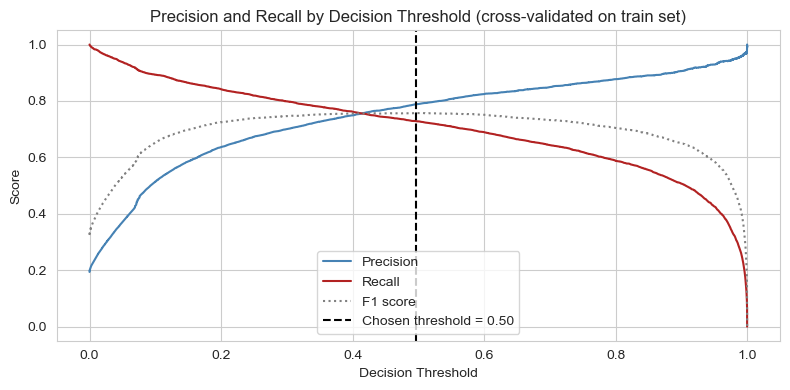

In [18]:
# Precision and recall at each threshold
plt.figure(figsize=(8, 4))
plt.plot(thresholds, precisions[:-1], label='Precision', color='steelblue')
plt.plot(thresholds, recalls[:-1], label='Recall', color='firebrick')
plt.plot(thresholds, f1_scores, label='F1 score', color='grey', linestyle=':')
plt.axvline(best_threshold, color='black', linestyle='--', label=f'Chosen threshold = {best_threshold:.2f}')
plt.title('Precision and Recall by Decision Threshold (cross-validated on train set)')
plt.xlabel('Decision Threshold')
plt.ylabel('Score')
plt.legend()
plt.tight_layout()
plt.savefig('../images/threshold.png', dpi=120)
plt.show()

**Comments**

* The threshold with the highest F1 score is 0.496, practically the same as the default of 0.5, and the scores are almost identical (F1 of 0.7575 against 0.7572). The model was trained with balanced class weights, which already shifts its predictions towards the toxic class, so the default threshold is close to the best one for F1.
* At this threshold, cross-validated recall is 0.729, below the target of 0.75. The chart shows the trade-off available: in cross-validation, recall reaches 0.75 at a threshold of about 0.43, where precision falls to about 0.76, still above its target of 0.70.
* The threshold was chosen in advance to maximise F1, and is kept at 0.496 for the evaluation below so that the test set does not influence the choice. Lowering it is discussed in the recommendations.

### 8. Evaluation on the test set

The test set is used here for the first time.

In [19]:
# Scores of the three tuned models on the test set at the default threshold of 0.5
test_scores = []
for name, grid in grids.items():
    y_pred = grid.best_estimator_.predict(X_test)
    proba = grid.best_estimator_.predict_proba(X_test)[:, 1]
    test_scores.append({'model': name,
                        'precision': precision_score(y_test, y_pred),
                        'recall': recall_score(y_test, y_pred),
                        'f1': f1_score(y_test, y_pred),
                        'average_precision': average_precision_score(y_test, proba),
                        'accuracy': accuracy_score(y_test, y_pred)})

pd.DataFrame(test_scores).set_index('model').round(4)

,precision,recall,f1,average_precision,accuracy
model,,,,,
Naive Bayes,0.7804,0.6318,0.6983,0.7626,0.8942
Random Forest,0.7015,0.7081,0.7048,0.7653,0.8850
Logistic Regression,0.7941,0.7435,0.7680,0.8308,0.9129


In [20]:
# Final model with the chosen threshold
proba_test = final_model.predict_proba(X_test)[:, 1]
y_pred_final = (proba_test >= best_threshold).astype(int)

print(classification_report(y_test, y_pred_final, target_names=['Not Toxic', 'Toxic'], digits=4))

              precision    recall  f1-score   support

   Not Toxic     0.9394    0.9531    0.9462      5286
       Toxic     0.7923    0.7443    0.7675      1271

    accuracy                         0.9126      6557
   macro avg     0.8658    0.8487    0.8569      6557
weighted avg     0.9109    0.9126    0.9116      6557



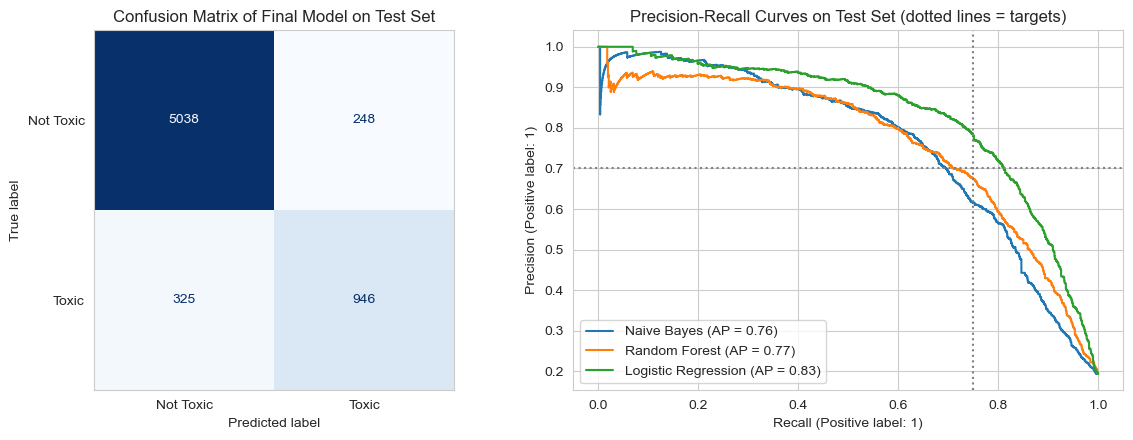

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_final, display_labels=['Not Toxic', 'Toxic'],
                                        cmap='Blues', colorbar=False, ax=ax[0])
ax[0].grid(False)
ax[0].set_title('Confusion Matrix of Final Model on Test Set')

for name, grid in grids.items():
    PrecisionRecallDisplay.from_predictions(y_test, grid.best_estimator_.predict_proba(X_test)[:, 1], name=name, ax=ax[1])
ax[1].axhline(0.70, color='grey', linestyle=':')
ax[1].axvline(0.75, color='grey', linestyle=':')
ax[1].set_title('Precision-Recall Curves on Test Set (dotted lines = targets)')

plt.tight_layout()
plt.savefig('../images/evaluation.png', dpi=120)
plt.show()

In [22]:
# Scores of the final model on the test set, by video
by_video = []
for video_id, group in test.assign(pred=y_pred_final).groupby('video_id'):
    by_video.append({'video_id': video_id,
                     'comments': len(group),
                     'toxic_share': group['is_toxic'].mean(),
                     'precision': precision_score(group['is_toxic'], group['pred']),
                     'recall': recall_score(group['is_toxic'], group['pred']),
                     'f1': f1_score(group['is_toxic'], group['pred'])})

pd.DataFrame(by_video).set_index('video_id').round(4)

,comments,toxic_share,precision,recall,f1
video_id,,,,,
1GyRS20MUmU,1504,0.1789,0.7833,0.6989,0.7387
d-tOb3SDeRw,1661,0.1915,0.7671,0.7767,0.7719
d3JkqJycmAg,1667,0.1956,0.7860,0.6871,0.7332
lrVIDuKvyMw,1725,0.2075,0.8271,0.8017,0.8142


**Comments**

**Final model (Logistic Regression, threshold of 0.496) on the test set of 6,557 comments:**

| Metric (toxic class) | Target | Score | Met? |
| --- | --- | --- | --- |
| Recall | at least 0.75 | **0.74** | No, narrowly missed |
| Precision | at least 0.70 | **0.79** | Yes |
| F1 score | above baseline of 0 | **0.77** | Yes |

|  | Predicted not toxic | Predicted toxic |
| --- | --- | --- |
| **Actual not toxic** | 5,038 | 248 |
| **Actual toxic** | 325 | 946 |

* **The precision target is met but the recall target is narrowly missed.** The model catches 74.4% of the toxic comments (target 75%), and 79% of the comments it flags are toxic. The F1 score on the test set (0.768) is in line with the cross-validated score (0.757), so the cross-validated scores were a reliable estimate.
* In practical terms, moderators would review 1,194 flagged comments instead of all 6,557 (a reduction of 82%). Of the 1,271 toxic comments, 325 (about 1 in 4) would slip through, and 248 harmless comments would be held for review.
* **Comparison of models:** Logistic Regression is the best on every metric on the test set, including average precision (0.83 against 0.76 and 0.77 for the other two), which summarises the precision-recall curve over all thresholds. Naive Bayes has the lowest recall (0.63), and Random Forest has the lowest precision (0.70) with recall of 0.71.
* **By video:** the F1 score ranges from 0.73 to 0.81. Recall is lowest for *We Broke Up* (0.69) and the *Blue Takis Mukbang* (0.70), and highest for the *Fire Noodle Mukbang* (0.80), so the model's performance depends somewhat on the video.
* The accuracy of 91.3% is above the baseline accuracy of 80.6%.
* **These scores measure agreement with the Detoxify labels**, as the test set is labeled by Detoxify. How the model compares with human judgement is checked in section 11.

### 9. What the model has learned

The words that each model relies on are compared below.

* **Logistic Regression:** the weight (coefficient) of each word. A positive weight pushes the prediction towards toxic and a negative weight pushes it towards not toxic.
* **Naive Bayes:** how many times more likely a word is to appear in a toxic comment than in a non-toxic one (shown as a log ratio), for words that appear at least 50 times.
* **Random Forest:** the importance of each word, i.e. how much the word helps the trees to separate the two classes. It does not show which class the word points to.

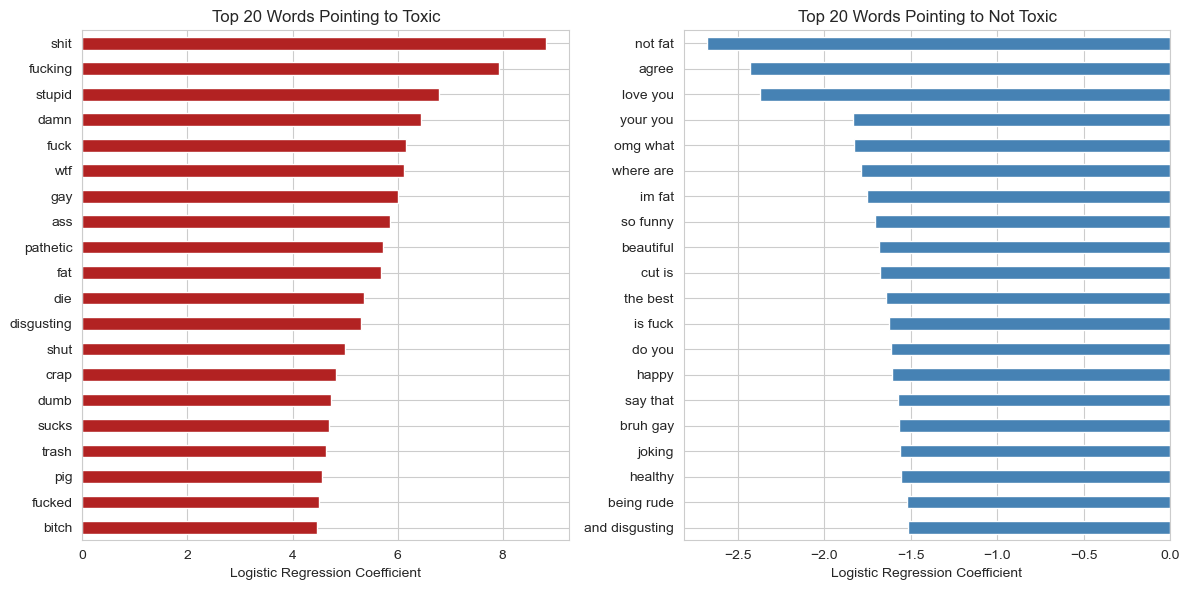

In [23]:
# Logistic Regression: words with the largest positive and negative weights
vec = final_model.named_steps['vec']
coefs = pd.Series(final_model.named_steps['lr'].coef_[0], index=vec.get_feature_names_out()).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(12, 6))

coefs.tail(20).plot(kind='barh', ax=ax[0], color='firebrick')
ax[0].set_title('Top 20 Words Pointing to Toxic')
ax[0].set_xlabel('Logistic Regression Coefficient')

coefs.head(20).sort_values(ascending=False).plot(kind='barh', ax=ax[1], color='steelblue')
ax[1].set_title('Top 20 Words Pointing to Not Toxic')
ax[1].set_xlabel('Logistic Regression Coefficient')

plt.tight_layout()
plt.savefig('../images/coefficients.png', dpi=120)
plt.show()

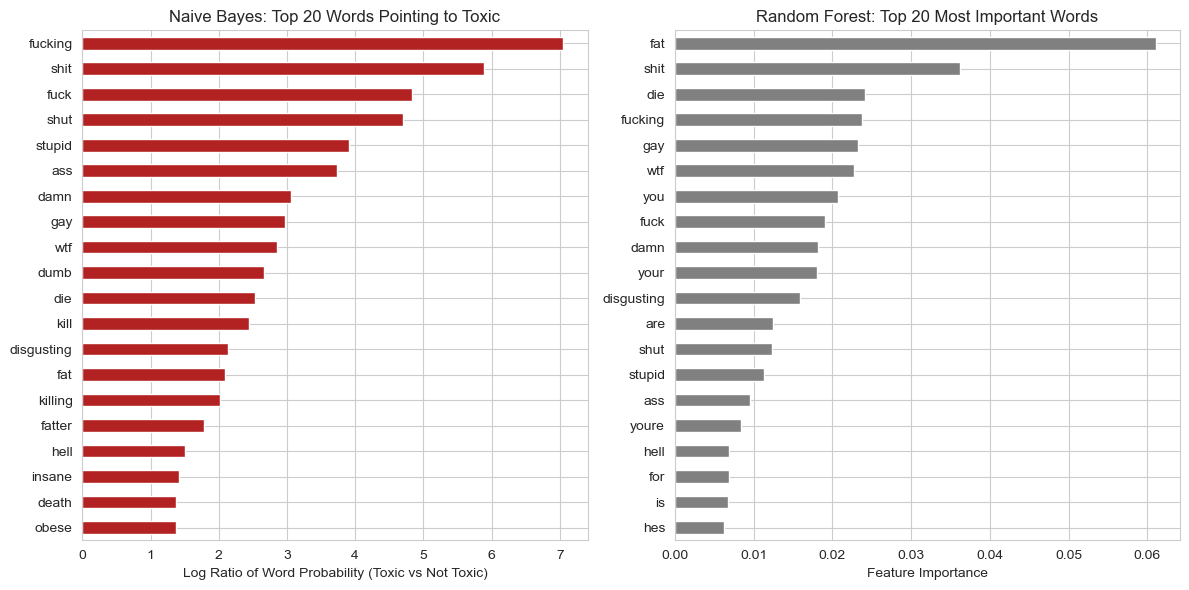

In [24]:
# Naive Bayes: words that are most over-represented in toxic comments
nb_vec = nb_grid.best_estimator_.named_steps['vec']
nb = nb_grid.best_estimator_.named_steps['nb']

log_ratio = pd.Series(nb.feature_log_prob_[1] - nb.feature_log_prob_[0], index=nb_vec.get_feature_names_out())
frequent = nb.feature_count_.sum(axis=0) >= 50

# Random Forest: most important words
rf_vec = rf_grid.best_estimator_.named_steps['vec']
importances = pd.Series(rf_grid.best_estimator_.named_steps['rf'].feature_importances_, index=rf_vec.get_feature_names_out())

fig, ax = plt.subplots(1, 2, figsize=(12, 6))

log_ratio[frequent].sort_values().tail(20).plot(kind='barh', ax=ax[0], color='firebrick')
ax[0].set_title('Naive Bayes: Top 20 Words Pointing to Toxic')
ax[0].set_xlabel('Log Ratio of Word Probability (Toxic vs Not Toxic)')

importances.sort_values().tail(20).plot(kind='barh', ax=ax[1], color='grey')
ax[1].set_title('Random Forest: Top 20 Most Important Words')
ax[1].set_xlabel('Feature Importance')

plt.tight_layout()
plt.show()

In [25]:
# How the final model scores a few example comments (written in lowercase without punctuation, like the cleaned text)
examples = pd.Series(['i love your videos they always make me smile',
                      'please take care of your health we are worried about you',
                      'you are a disgusting fat pig',
                      'ur so st00pid and ugly'])

pd.DataFrame({'comment': examples,
              'probability_toxic': final_model.predict_proba(examples)[:, 1].round(3),
              'flagged': (final_model.predict_proba(examples)[:, 1] >= best_threshold).astype(int)})

,comment,probability_toxic,flagged
0,i love your videos they always make me smile,0.006,0
1,please take care of your health we are worried about you,0.001,0
2,you are a disgusting fat pig,1.000,1
3,ur so st00pid and ugly,0.953,1


**Comments**

* **Words pointing to toxic:** all three models rely heavily on the same words - profanities and slurs, insults ('stupid', 'pathetic', 'dumb', 'disgusting', 'trash', 'pig'), 'fat', and words about death ('die', 'kill').
* **Words pointing to not toxic:** words of appreciation and agreement ('agree', 'love you', 'so funny', 'beautiful', 'the best', 'happy', 'joking').
* **Bigrams add context.** The strongest non-toxic feature is 'not fat', and 'im fat' is also among them: bigrams that soften a word which is otherwise toxic. This is something that Naive Bayes and Random Forest, tuned on single words, could not capture, and helps to explain why Logistic Regression with bigrams performed best.
* **Sign of overfitting.** A few bigrams that contain a toxic word also have strong negative weights (e.g. 'is fuck', 'and disgusting'). These cancel out the weight of the toxic word for particular comments in the train set rather than reflecting a general pattern, which is consistent with the large gap between the train and cross-validated scores.
* **Stop words matter.** The most important words in the Random Forest include 'you', 'your', 'youre' and 'are'. This is consistent with the finding in section 4 that removing stop words makes the models worse: whether a comment is aimed at someone is part of what makes it toxic.
* In the examples, the model gives a probability close to 0 to a supportive comment (0.006) and to a comment expressing concern about health (0.001), and flags a direct insult (1.000). It also flags the comment with a misspelt insult ('st00pid', 0.953), but because of the other words in it such as 'ugly'. A misspelt word on its own would not be recognised.
* **Domain knowledge:** on this channel, 'fat' and words about dying are used both to attack the creator and to express worry about his health. The model treats these words as toxic in most contexts, which is the main source of the errors below.

### 10. Error analysis

In [26]:
errors = test[['text', 'toxicity', 'is_toxic']].copy()
errors['proba'] = proba_test
errors['pred'] = y_pred_final

false_negatives = errors[(errors['is_toxic'] == 1) & (errors['pred'] == 0)]
false_positives = errors[(errors['is_toxic'] == 0) & (errors['pred'] == 1)]

print(f'False negatives (toxic comments missed): {len(false_negatives)}')
print(f'False positives (non-toxic comments flagged): {len(false_positives)}')

False negatives (toxic comments missed): 325
False positives (non-toxic comments flagged): 248


In [27]:
# Toxic comments that the model missed
false_negatives[['text', 'toxicity', 'proba']].sample(12, random_state=42).round(2)

,text,toxicity,proba
7166,Me eating my Takis and you ruined mi Takis,0.75,0.25
9276,I don’t feel bad seeing u struggle with ur fatness,0.86,0.31
29623,The part when Nick bent down near his motor(scooter)...he looks like a bull frog😂,0.56,0.08
618,bro is having a diarrhea,0.54,0.44
2089,Nazi Muslim the Muslim had to so that has a Hazard,0.70,0.01
14481,Nick is black,0.88,0.28
16684,What are you a cammel water weight might as well call that a hump,0.53,0.04
28085,I think he's a psychopath,0.93,0.21
26162,dude they cryin they got into a figjt i 🤔 think,0.58,0.04
5762,"Bro, no one wants you on their shirt",0.61,0.04


In [28]:
# Non-toxic comments that the model flagged
false_positives[['text', 'toxicity', 'proba']].sample(12, random_state=42).round(2)

,text,toxicity,proba
2437,Me and he is not fat,0.36,0.57
7386,HEY MAMA LOOK IS THIS WHAT HAPPENS WHEN U DON’T EAT UR VEGIES?\nMom: Yes sweetie,0.33,0.89
2068,Guys pls stop hating on them ik they might be overweight but at least they are happy that's all that matters. if u keep on hating then that's just gonna interfear with their happiness,0.24,0.54
25312,Stop you mean bullshit😂,0.00,0.83
32064,I hate Nikocado avocado show some respect,0.35,0.92
5750,“Diet soda cancels out fat” 😂😂😂😂😂😂😂😂😂😂,0.43,0.93
22095,15:13 he looked so cuteeeeeeeeeeee omgggggggggggg,0.04,0.57
10403,Also we are the ones that watch your video so you have no reason to be calling people poor when you’re literally living off food stamps,0.29,0.97
23488,You should probably get professional help with you’re overweight problem... and eat healthier 👀,0.50,0.57
12017,When are you going to go back to being vegan?,0.07,0.88


In [29]:
# Are the errors on comments where the Detoxify score itself was borderline (between 0.3 and 0.7)?
borderline = errors['toxicity'].between(0.3, 0.7)
wrong = errors['is_toxic'] != errors['pred']

print(f'Share of test comments with borderline toxicity score: {borderline.mean():.1%}')
print(f'Share of errors that are on borderline comments: {borderline[wrong].mean():.1%}')
print(f'Error rate on borderline comments: {wrong[borderline].mean():.1%}')
print(f'Error rate on other comments: {wrong[~borderline].mean():.1%}')

Share of test comments with borderline toxicity score: 10.5%
Share of errors that are on borderline comments: 48.2%
Error rate on borderline comments: 40.0%
Error rate on other comments: 5.1%


**Comments**

* **Errors are concentrated on borderline comments.** Comments with a Detoxify score between 0.3 and 0.7 make up 10.5% of the test set but 48.2% of the errors. The model is wrong on 40.0% of these comments, compared to 5.1% of the rest. For these comments the label itself is uncertain, so part of the 'errors' are disagreements on comments that could reasonably be labeled either way.
* **Toxic comments that were missed (false negatives)** are typically:
    * Mockery without an obviously toxic word (e.g. 'he looks like a bull frog', 'What are you a cammel water weight might as well call that a hump', 'Bro, no one wants you on their shirt').
    * Insults using words that are rare in the data (e.g. 'psychopath') or misspelt.
    * Some are errors in the labels rather than the model. 'Nick is black' was given a toxicity score of 0.88 because the Detoxify `original` model is known to associate identity terms with toxicity, and a viewer criticising other viewers for being cruel was also labeled toxic.
* **Non-toxic comments that were flagged (false positives)** are typically:
    * Comments which use a trigger word without hostility, such as 'not fat', 'overweight' or 'hating', including viewers defending the creator ('Guys pls stop hating on them ik they might be overweight but at least they are happy').
    * Jokes and comments in capital letters.
    * Some flagged comments are arguably toxic even though Detoxify scored them below 0.5 (e.g. 'I hate Nikocado avocado show some respect').
* A model based on word counts cannot tell tone from vocabulary. This is the main limit on its performance, and would need a model that reads words in context (such as the BERT model behind Detoxify) to overcome.

### 11. Check against manual labels

The labels used above come from Detoxify. The 300 comments in `data/gold_sample.csv` (see Notebook 2) were labeled manually, by one person, and are compared here with the Detoxify labels and with the final model's predictions.

* **Agreement** is the share of comments where the two labels are the same.
* **Precision** and **recall** treat the manual labels as the truth, e.g. precision of the Detoxify labels is the share of comments labeled toxic by Detoxify that were also labeled toxic manually.
* **Cohen's kappa** measures agreement beyond what would be expected by chance: 0 means no better than chance and 1 means perfect agreement. Values between 0.2 and 0.4 are usually described as fair and between 0.6 and 0.8 as substantial.
* The final model is only compared on the labeled comments that are in the **test set**. The other labeled comments were used to train it, and it reproduces the Detoxify labels of those comments almost exactly, so they would not show how it performs on new comments.

In [30]:
gold = pd.read_csv('../data/gold_sample.csv')
gold = gold.dropna(subset=['human_is_toxic'])

if len(gold) == 0:
    print('The sample has not been labeled manually yet.')
else:
    gold = gold.merge(df[['comment_id', TEXT_COL, 'toxicity', 'is_toxic']], on='comment_id')
    gold['human_is_toxic'] = gold['human_is_toxic'].astype(int)
    gold['in_test'] = gold['comment_id'].isin(test['comment_id'])
    gold['pred'] = (final_model.predict_proba(gold[TEXT_COL])[:, 1] >= best_threshold).astype(int)

    in_train = gold[~gold['in_test']]
    print(f"Comments labeled manually: {len(gold)}, of which {gold['human_is_toxic'].sum()} labeled toxic")
    print(f"Labeled comments in the test set: {gold['in_test'].sum()}")
    print(f"Final model agrees with the Detoxify labels on {(in_train['pred'] == in_train['is_toxic']).mean():.1%} "
          f"of the labeled comments in the train set")

Comments labeled manually: 300, of which 107 labeled toxic
Labeled comments in the test set: 51
Final model agrees with the Detoxify labels on 99.2% of the labeled comments in the train set


In [31]:
def compare(human, other):
    """Agreement, precision, recall and Cohen's kappa of a set of labels against the manual labels."""
    return {'comments': len(human),
            'toxic_manual': human.sum(),
            'agreement': accuracy_score(human, other),
            'precision': precision_score(human, other),
            'recall': recall_score(human, other),
            'kappa': cohen_kappa_score(human, other)}


test_gold = gold[gold['in_test']]

pd.DataFrame({'Detoxify labels (all labeled comments)': compare(gold['human_is_toxic'], gold['is_toxic']),
              'Detoxify labels (test set only)': compare(test_gold['human_is_toxic'], test_gold['is_toxic']),
              'Final model (test set only)': compare(test_gold['human_is_toxic'], test_gold['pred'])}).T.round(3)

,comments,toxic_manual,agreement,precision,recall,kappa
Detoxify labels (all labeled comments),300.0,107.0,0.610,0.467,0.654,0.220
Detoxify labels (test set only),51.0,14.0,0.608,0.385,0.714,0.223
Final model (test set only),51.0,14.0,0.647,0.417,0.714,0.275


In [32]:
# The sample has 50 comments from each range of Detoxify score, so comments with high scores are over-represented.
# Weighting each range by its share of all comments gives an estimate of the agreement on the whole data.
bins = [0, 0.1, 0.3, 0.5, 0.7, 0.9, 1]
bands = gold.groupby(pd.cut(gold['toxicity'], bins=bins, include_lowest=True)).agg(
    labeled=('human_is_toxic', 'size'), manual_toxic_share=('human_is_toxic', 'mean'))
bands['share_of_all_comments'] = pd.cut(df['toxicity'], bins=bins, include_lowest=True).value_counts(normalize=True).sort_index()
bands['detoxify_label'] = [int(band.left >= 0.5) for band in bands.index]

weight = bands['share_of_all_comments']
toxic_share = bands['manual_toxic_share']
flagged = bands['detoxify_label'] == 1

estimated_toxic = (weight * toxic_share).sum()
estimated_both = (weight[flagged] * toxic_share[flagged]).sum()
print(f'Estimated share of all comments that are toxic by the manual labels: {estimated_toxic:.1%} (Detoxify labels: {weight[flagged].sum():.1%})')
print(f'Estimated precision of the Detoxify labels: {estimated_both / weight[flagged].sum():.3f}')
print(f'Estimated recall of the Detoxify labels: {estimated_both / estimated_toxic:.3f}')
print(f'Estimated agreement: {estimated_both + (weight[~flagged] * (1 - toxic_share[~flagged])).sum():.3f}')

bands.round(3)

Estimated share of all comments that are toxic by the manual labels: 24.0% (Detoxify labels: 19.4%)
Estimated precision of the Detoxify labels: 0.484
Estimated recall of the Detoxify labels: 0.391
Estimated agreement: 0.754


,labeled,manual_toxic_share,share_of_all_comments,detoxify_label
toxicity,,,,
"(-0.001, 0.1]",50,0.16,0.645,0
"(0.1, 0.3]",50,0.22,0.108,0
"(0.3, 0.5]",50,0.36,0.053,0
"(0.5, 0.7]",50,0.30,0.051,1
"(0.7, 0.9]",50,0.48,0.072,1
"(0.9, 1.0]",50,0.62,0.071,1


In [33]:
# Comments labeled toxic by Detoxify but not toxic manually
gold[(gold['is_toxic'] == 1) & (gold['human_is_toxic'] == 0)][['text', 'toxicity']].sample(10, random_state=1).round(2)

,text,toxicity
241,WHY U ACTING LIKE THAT IN PUBLIC...keep ur mask on and fix ur attitude boyyyy wtf 💀,0.76
111,Plus stop this tout kill you,0.97
121,bro why do u want to get famous and always 0:45 treat him so annoying and mad srsly grow up and get a life im not jking actually you have even treated him really bad and U dont even care abt him?d...,0.55
268,Man who ruined your life why can’t you get out of it? Are you guys dating or something no break up stupid,0.96
178,@mmidas580 like I give a damn what ignorant people think of me. 😂😂,0.96
180,Wtf is this?,0.79
204,Get out of Orlin´s house,0.60
282,This sh it wack,0.69
152,"@khaditofi3367 Lol just about every other month, this guy is a notoriously infamous clown.",0.71
280,Of all those shits,0.95


In [34]:
# Comments labeled toxic manually but not toxic by Detoxify
gold[(gold['is_toxic'] == 0) & (gold['human_is_toxic'] == 1)][['text', 'toxicity']].sample(10, random_state=1).round(2)

,text,toxicity
20,"Doctor: ""Your weight gain has caused high blood pressure, back pain, breathing problems and put you at a great risk for diabetes and heart disease. I doubt you will live longer that two years.""\nN...",0.11
212,Don't worry he won't be here for long,0.00
30,"Nick ""I'm morbidly obese"" also nick "" it's just water weight""",0.05
140,yes and we are not fat shaming unless it is nickado avocado,0.34
179,"he is skinny, just look at his videos he is actually skinny now",0.47
189,Somebody give this guy an adderall,0.01
124,Rip,0.36
292,Are you an adult,0.40
116,toxic human,0.42
174,Well you look Bonnie the dinosaur if he was your mom 👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎🎅,0.22


**Comments**

**Detoxify labels against the manual labels**

* Of the 300 comments, 107 were labeled toxic manually. The Detoxify labels agree with the manual labels on 61% of them, with Cohen's kappa of 0.22, which is only **fair agreement**.
* The sample has 50 comments from each range of Detoxify score, so it over-represents comments with high scores. Weighting each range by its share of all comments gives a rough estimate for the whole data (each range has only 50 comments, so these estimates are uncertain):
    * About 24% of all comments would be toxic by the manual labels, compared to 19.4% by the Detoxify labels.
    * **Precision of about 0.48:** only about half of the comments that Detoxify labels toxic are toxic by the manual labels.
    * **Recall of about 0.39:** Detoxify labels only about 4 in 10 of the comments that are toxic by the manual labels.
    * Overall agreement is about 75%. This is higher than in the sample because most comments are clearly not toxic and both agree on these.
* The main source of missed toxic comments is the lowest range of scores (below 0.1). It contains 65% of all comments, and 16% of the sampled comments in this range were labeled toxic manually. Even in the highest range of scores (above 0.9), only 62% of the sampled comments were labeled toxic manually.

**Where the two disagree**

* **Labeled toxic by Detoxify, but not manually:** mostly casual profanity that is not aimed at anyone ('Wtf is this?', 'This sh it wack', 'Of all those shits') and blunt criticism of behaviour ('fix ur attitude', 'grow up and get a life').
* **Labeled toxic manually, but not by Detoxify:** mockery and veiled hostility towards the creator that uses no offensive words, such as 'Don't worry he won't be here for long' (Detoxify score of 0.00), 'Somebody give this guy an adderall' (0.01), 'Are you an adult' (0.40) and a mock doctor's warning that he will not live two more years (0.11).
* In other words, the two use different definitions: Detoxify reacts mainly to offensive words, while the manual labels judge whether a comment is meant to demean or hurt the creator. On a channel where much of the hostility is mockery of the creator's weight and health, this difference matters.

**Final model against the manual labels**

* On the 51 labeled comments in the test set, the final model agrees with the manual labels on 65% of comments (kappa of 0.28), with precision of 0.42 and recall of 0.71. This is similar to the Detoxify labels on the same comments (agreement of 61%, kappa of 0.22). With only 51 comments, of which 14 are toxic, the difference between the two is too small to be meaningful: one comment changes recall by 0.07.
* As expected, the model agrees with the Detoxify labels on 99.2% of the labeled comments in the train set, which is why these are left out of the comparison.
* **The model learns Detoxify's judgement, including its errors.** Its test scores in section 8 (precision of 0.79, recall of 0.74) measure how well it reproduces Detoxify, and its agreement with human judgement is no better than Detoxify's own.

**Caveats:** the manual labels are from one person, so they reflect one person's definition of toxic, and 300 comments is a small sample. Labels from several people, with a written definition agreed with the community team, would be needed to confirm these findings.

### 12. Conclusion and recommendations

**Conclusion**

The goal was to build a model that predicts whether a YouTube comment is toxic, so that toxic comments can be held automatically for review by a moderator.

* 40,000 comments were collected from four videos (10,000 each), cleaned to 32,783 unique comments and labeled with Detoxify (19.4% toxic).
* Three models were tuned and compared with cross-validation. **Logistic Regression** on word and bigram counts was the best (CV F1 score of 0.757), ahead of Random Forest (0.707) and Naive Bayes (0.703).
* Against the Detoxify labels of the test set, the final model achieved **precision of 0.79**, meeting its target of 0.70, and **recall of 0.74**, narrowly missing its target of 0.75. Its F1 score of 0.77 compares to 0 for a baseline that catches no toxic comments.
* Keeping stop words and adding bigrams improved the model, as words such as 'you' and phrases such as 'not fat' carry information on whether a comment is an attack. Stemming and lemmatization made little difference.
* **However, the check against 300 manually labeled comments shows that the Detoxify labels agree only fairly with human judgement** (Cohen's kappa of 0.22). Across all comments, Detoxify is estimated to label only about 4 in 10 of the comments that are toxic by the manual labels, and only about half of the comments it labels toxic are toxic by the manual labels. Detoxify reacts mainly to offensive words, while much of the hostility on this channel is mockery without them. The model reproduces Detoxify's labels, so it inherits this gap.
* **The problem statement is therefore only partly answered.** The project shows that a simple, fast model can reproduce a toxicity labeller closely, but not yet that it can detect what the community team would consider toxic.

**Recommendations for the community team**

* **Do not rely on the model for moderation yet.** Its precision and recall against the team's own judgement are likely to be well below the targets.
* **Agree on a written definition of toxic and label comments manually.** The definition should say whether, for example, casual profanity and mockery of the creator count as toxic. A few thousand comments labeled by two or more moderators would be enough to retrain and evaluate the same pipeline on labels that reflect the team's judgement. The 300 comments labeled for this project are a starting point.
* **Set the decision threshold on the manual labels.** The threshold of about 0.43 that meets the recall target on the Detoxify labels is unlikely to carry over.
* **If the model is used in the meantime, use it only to hold comments for review, never to delete them.** It will mostly flag comments with offensive words, including harmless profanity, and miss mockery, so viewer reports remain essential.
* The pipeline itself is cheap to reuse: the model trains in about a second and scores comments without a GPU, so it can be retrained easily as manual labels are added.

**Limitations**

* **The labels come from a model, and agree only fairly with human judgement.** The model's scores measure how well it reproduces Detoxify's labels, which miss much of the mockery on this channel and flag harmless profanity, and which also score some identity terms as toxic.
* **The manual check is small.** It is based on 300 comments labeled by one person, and only 51 of them are in the test set, so the estimates are uncertain and reflect one person's definition of toxic.
* **One creator only.** All comments are from one channel, where the vocabulary is specific (food, weight, health). The model may not perform as well on other channels.
* **Tone and context.** The model relies on individual words and pairs of words, so it misses mockery and misspelt insults, and flags harmless uses of words such as 'fat'.
* **Data coverage.** The comments are the 10,000 most recent of each video, so the first year of comments on the Blue Takis mukbang is not included; at most 5 replies were collected per thread; and comments with only emojis or non-latin scripts cannot be classified.
* **Overfitting.** The final model fits the train set much better than unseen data (F1 score of 0.99 against 0.76), although its score on unseen data was still the best and was confirmed on the test set.

**Next steps**

1. Agree on a definition of toxic with the community team, label a few thousand comments manually with at least two people per comment, and measure their agreement with each other.
2. Retrain and evaluate the models on the manual labels, and choose the decision threshold on them.
3. Compare other labellers against the manual labels, e.g. Detoxify's `unbiased` model or a large language model given the team's definition, to see if any of them could label comments more cheaply with acceptable agreement.
4. Add videos from other creators to test how well the model generalises.
5. Try features that capture more context, such as character n-grams for misspellings, emojis, or a fine-tuned pre-trained language model, which is better able to recognise mockery that uses no offensive words.